# RBC NOB 중간과정 점검 — 여러 케이스 동시

`run_configurations` 에 적힌 케이스마다 `../log/` 모니터 블록(+ 있으면
`../stats_nob_*/` 프로파일)을 읽어 **케이스별 패널 + 케이스 겹친 비교 그림**을
그린다. **돌고 있는 런도 아무 때나** 실행해도 된다 — 로그만 있으면 그려지고,
통계 파일이 없으면 프로파일 패널만 조용히 건너뛴다.

ΔT·Ra·격자는 **ini 가 아니라 로그 머리글**(`# NOB glycerol: Ra=... DeltaT=...K |
128x128x256, dz_wall=...`)에서 읽는다 — ini 는 런 이후 수정됐을 수 있고, 한
로그에 스모크(32³)와 본런이 같이 들어 있는 경우도 많다. 그래서 모니터 블록은
**블록별로 자기 머리글을 들고 있고**, `block=` 으로 고를 수 있다 (기본 −1 = 마지막
= 본런).

| 패널 | 보는 것 | 기대 |
|---|---|---|
| θ_c(t) | 플래토 접근 | Horn 참조 CSV 를 ΔT 로 보간한 값에 수렴 (ΔT 20/40/60K → 0.0612/0.1383/0.1527) |
| dt(t), div(t) | 안정성 | dt 유계, div ~1e-14 |
| T 범위 | 클립 건강 | [−0.5, 0.5] 안, 벽값에 밀착 |
| 케이스 비교 | ΔT 의존성 | θ_c/θ_Horn 이 케이스 무관하게 1 로 모임 |
| T_mean(z) | NOB 비대칭 | 상·하 경계층 두께 비대칭 (**접기 평균 금지** — 비대칭이 신호다) |

θ_c 목표는 `../../rbc/plot/Horm.csv` (1열 ΔT[K], 2열 θ_c·ΔT[K]) 를 ΔT 로 보간해
ΔT 로 나눠 무차원화한 값이다.

In [5]:
import glob, math, os, re
import numpy as np
import matplotlib
try:                                   # 노트북: 저장 + 화면 동시
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:                      # 스크립트/배치 실행 (DISPLAY 없음)
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

# ── 케이스 목록 ────────────────────────────────────────────────────────────
#   log_glob   : 가장 최근 파일을 쓴다 (여러 잡 ID 가 매칭되면 마지막 것)
#   stats_glob : 없거나 파일이 아직 없으면 프로파일 패널만 건너뛴다
#   block      : 로그 안 모니터 블록 번호 (기본 −1 = 마지막 = 본런, 0 = 스모크)
#   fig9       : False 면 fig9 산점도에서 뺀다 (스모크처럼 비교 대상이 아닌 런)
# 새 케이스를 돌렸으면 여기에 한 줄 추가하면 된다 — 셀 맨 끝의 "미등록 로그"
# 알림이 빠진 로그를 짚어 준다.
run_configurations = [
    dict(label="dt40", log_glob="../log/rbc_nob_dt40_*.log",
         stats_glob="../stats_nob_dt40/rbc_nob_stats_*.dat"),
    dict(label="dt20", log_glob="../log/rbc_nob_dt20_*.log",
         stats_glob="../stats_nob_dt20/rbc_nob_stats_*.dat"),
    dict(label="dt60", log_glob="../log/rbc_nob_dt60_*.log",
         stats_glob="../stats_nob_dt60/rbc_nob_stats_*.dat"),
    dict(label="dt60_fix", log_glob="../log/rbc_nob_dt60_fix_*.log",
         stats_glob="../stats_nob_dt60/stats_nob_dt60_fix*.dat"),
    # 이전 dt40 런 (잡 35327, t=9199 에서 취소). stats_start_time 16900 전에
    # 끊겼으니 통계 파일은 없다 — 모니터 궤적만 비교용으로 들고 온다.
    # dict(label="dt40_prev(35327)", log_glob="../log/rbc_nob_gpu_35327.log"),
    # # 같은 로그의 0번 블록 = 32^3 스모크 (본런과 섞이지 않게 따로 뽑는다)
    # dict(label="smoke(32^3)", log_glob="../log/rbc_nob_gpu_35327.log", block=0,
    #      stats_glob="../stats_nob_smoke/rbc_nob_stats_*.dat", fig9=False),
]

MONITOR_COLUMNS = 9      # step time dt max|div| theta_c Nu Tmin Tmax sec/step

# ── Horn 참조 (fig9 CSV: ΔT[K], θ_c·ΔT[K]) ────────────────────────────────
horn_reference = np.genfromtxt("../../rbc/plot/Horm.csv", delimiter=",")

def horn_theta_c(delta_temperature):
    """ΔT[K] → 무차원 θ_c 목표 (CSV 2열은 K 단위라 ΔT 로 나눈다)."""
    return float(np.interp(delta_temperature, horn_reference[:, 0],
                           horn_reference[:, 1])) / delta_temperature

def load_monitor_blocks(log_path):
    """로그 하나 → 모니터 블록 리스트. 각 블록은 **바로 앞 '# NOB glycerol'
    머리글**의 ΔT·Ra·격자를 자기 메타로 들고 온다 (스모크+본런 혼재 대응)."""
    blocks, current, meta = [], None, {}
    for line in open(log_path):
        if "DeltaT=" in line:                       # 런 머리글 — 다음 블록의 메타
            found = re.search(r"DeltaT=([\d.]+)K", line)
            if found:
                meta = dict(delta_temperature=float(found.group(1)))
                rayleigh = re.search(r"Ra=([\d.eE+-]+)", line)
                prandtl = re.search(r"Pr=([\d.eE+-]+)", line)
                grid = re.search(r"\|\s*(\d+x\d+x\d+), dz_wall=([\d.eE+-]+)", line)
                if rayleigh: meta["rayleigh"] = float(rayleigh.group(1))
                if prandtl: meta["prandtl"] = float(prandtl.group(1))
                if grid: meta.update(grid=grid.group(1), dz_wall=float(grid.group(2)))
        if line.lstrip().startswith("# step"):
            current = dict(meta, rows=[]); blocks.append(current); continue
        parts = line.split()
        if current is not None and len(parts) == MONITOR_COLUMNS:
            try: current["rows"].append([float(x) for x in parts])
            except ValueError: pass
    return [dict(b, monitor=np.array(b["rows"])) for b in blocks if b["rows"]]

def load_profile(stats_glob):
    """최신 통계 파일 → (헤더 dict, z/T_mean/w_rms/wT 배열). 없으면 None."""
    paths = sorted(glob.glob(stats_glob)) if stats_glob else []
    if not paths:
        return None
    header, rows = {}, []
    for line in open(paths[-1]):
        if line.startswith("#"):
            for key, value in re.findall(r"(\w+)=([-\d.eE+]+)", line):
                header[key] = float(value)
            continue
        rows.append([float(x) for x in line.split()])
    data = np.array(rows)
    return dict(path=paths[-1], header=header, n_snapshots=len(paths), paths=paths,
                z=data[:, 0], temperature_mean=data[:, 1], w_rms=data[:, 2],
                wt_mean=data[:, 3])

def boundary_layer_thicknesses(z, temperature_mean, theta_c):
    """벽 기울기 자로 잰 열 경계층 두께 (하/상). NOB 비대칭의 정량 지표 —
    λ = (T_wall − θ_c) / |dT/dz|_wall, 벽값 ±0.5 과 첫/마지막 중심셀로 근사."""
    slope_bottom = (0.5 - temperature_mean[0]) / z[0]
    slope_top = (temperature_mean[-1] - (-0.5)) / (1.0 - z[-1])
    lambda_bottom = (0.5 - theta_c) / max(slope_bottom, 1e-30)
    lambda_top = (theta_c + 0.5) / max(slope_top, 1e-30)
    return lambda_bottom, lambda_top

def attach_window(run):
    """통계 누적 구간(어디서 어디까지 평균했나)을 복원해 run 에 붙인다.

    정본은 **통계 파일 헤더**다 — 누적은 t >= stats_start_time 부터 **매 스텝**
    (main.cpp:348 `++samples`) 이므로  시작 스텝 = step − samples + 1.
    ini 의 stats_start_time 은 런 이후 수정됐을 수 있어 쓰지 않는다.
    모니터의 Nu 열은 samples>0 일 때만 0 이 아니므로(main.cpp:225
    running_nusselt) **독립 검증**이 된다 — 둘이 monitor_interval 이내로
    맞는지 확인해 어긋나면 경고한다.
    시작 시각은 모니터의 step↔time 보간으로 되돌린다 (끝 시각은 헤더에 있다)."""
    run["window"] = None
    started = run["nusselt"] > 0
    run["nusselt_start_time"] = float(run["time"][started][0]) if started.any() else None
    profile = run["profile"]
    if profile is not None and {"step", "samples", "t"} <= set(profile["header"]):
        header = profile["header"]
        end_step, n_samples = int(header["step"]), int(header["samples"])
        start_step = end_step - n_samples + 1
        start_time = float(np.interp(start_step, run["step"], run["time"]))
        run["window"] = dict(
            source="stats header", start_step=start_step, end_step=end_step,
            n_samples=n_samples, start_time=start_time, end_time=float(header["t"]),
            duration=float(header["t"]) - start_time,
            # 끝 시각은 헤더 t 그대로라 정확하다. 시작만 모니터 보간이고, 누적
            # 시작이 모니터 첫 행보다 앞서면(재시작 런) 외삽이라 '~' 를 붙인다.
            clipped=bool(start_step < run["step"][0] - 0.5),
            n_snapshots=profile["n_snapshots"])
        if run["nusselt_start_time"] is not None:
            gap = abs(run["nusselt_start_time"] - start_time)
            span = float(np.median(np.diff(run["time"]))) if len(run["time"]) > 1 else 0.0
            if gap > 2 * max(span, 1e-12):
                print(f"  [{run['label']}] ⚠ 누적 시작 불일치: 헤더 복원 "
                      f"t={start_time:.1f} vs 모니터 Nu>0 "
                      f"t={run['nusselt_start_time']:.1f} (차 {gap:.1f})")
    elif run["nusselt_start_time"] is not None:
        # 누적은 돌고 있는데 아직 파일을 안 썼다 — 모니터로만 구간을 잡는다
        run["window"] = dict(
            source="monitor Nu>0", start_step=None, end_step=int(run["step"][-1]),
            n_samples=None, start_time=run["nusselt_start_time"],
            end_time=float(run["time"][-1]),
            duration=float(run["time"][-1]) - run["nusselt_start_time"],
            clipped=False, n_snapshots=0)
    return run["window"]

def window_text(run):
    """그림 꼬리말 한 줄 — ASCII 만 (DejaVu Sans 에 한글 글리프 없음)."""
    window = run["window"]
    if window is None:
        start, end = run["tail_window"]
        return (f"{run['label']}: no stats window yet (t < stats_start_time) - "
                f"theta_c from monitor tail t {start:.0f}-{end:.0f}")
    text = (f"{run['label']}: stats accumulated t "
            f"{'~' if window['clipped'] else ''}{window['start_time']:.1f}"
            f"-{window['end_time']:.1f}  (dt {window['duration']:.1f} free-fall")
    if window["n_samples"]:
        text += f", {window['n_samples']} samples every step"
    text += f", {window['source']})"
    if window["start_step"] is not None:
        text += f"  |  step {window['start_step']}-{window['end_step']}"
        if window["n_snapshots"]:
            text += f", {window['n_snapshots']} snapshots"
    return text

def annotate_windows(figure, annotated_runs, fontsize=7):
    """모든 그림 하단에 '어디서 어디까지 평균했나' 를 같은 형식으로 적는다."""
    lines = [window_text(run) for run in annotated_runs]
    figure.text(0.5, 0.006, "\n".join(lines), ha="center", va="bottom",
                fontsize=fontsize, color="0.35", linespacing=1.5)

def shade_window(axis, run, label=None):
    """누적 구간을 음영 띠 + 점선 경계로 표시. 구간이 없으면 아무것도 안 한다."""
    window = run["window"]
    if window is None:
        return
    axis.axvspan(window["start_time"], window["end_time"], color="tab:purple",
                 alpha=0.12, zorder=0, label=label)
    for boundary in (window["start_time"], window["end_time"]):
        axis.axvline(boundary, color="tab:purple", lw=0.8, ls=":", zorder=1)

def load_run(configuration):
    label = configuration["label"]
    log_paths = sorted(glob.glob(configuration["log_glob"]))
    if not log_paths:
        print(f"[{label}] 로그 없음 ({configuration['log_glob']}) — 런 시작 후 재실행")
        return None
    log_path = log_paths[-1]
    blocks = load_monitor_blocks(log_path)
    if not blocks:
        print(f"[{label}] 모니터 행 없음 ({log_path})"); return None
    index = configuration.get("block", -1)
    if index >= len(blocks) or index < -len(blocks):
        print(f"[{label}] 블록 {index} 없음 — 로그에 {len(blocks)}개뿐 ({log_path})")
        return None
    block = blocks[index]
    monitor = block["monitor"]
    run = dict(configuration, **{k: v for k, v in block.items() if k != "rows"})
    run.update(log_path=log_path, n_blocks=len(blocks), block_index=index,
               step=monitor[:, 0], time=monitor[:, 1], dt=monitor[:, 2],
               divergence=monitor[:, 3], theta_c=monitor[:, 4],
               nusselt=monitor[:, 5], temperature_min=monitor[:, 6],
               temperature_max=monitor[:, 7], seconds_per_step=monitor[:, 8])
    run["theta_target"] = horn_theta_c(run["delta_temperature"])
    # 최근 20% 창의 평균·기울기 → 플래토 판정
    tail = run["time"] > run["time"][0] + 0.8 * (run["time"][-1] - run["time"][0])
    if tail.sum() >= 2:
        run["tail_mean"] = float(run["theta_c"][tail].mean())
        run["tail_slope"] = float(np.polyfit(run["time"][tail], run["theta_c"][tail], 1)[0])
    else:
        run["tail_mean"], run["tail_slope"] = float(run["theta_c"][-1]), float("nan")
    run["plateau"] = abs(run["tail_slope"]) < 1e-5
    run["tail_window"] = (float(run["time"][tail][0]), float(run["time"][-1])) \
        if tail.sum() >= 2 else (float(run["time"][0]), float(run["time"][-1]))
    run["profile"] = load_profile(configuration.get("stats_glob"))
    attach_window(run)
    print(f"[{label}] {os.path.basename(log_path)} 블록 {index}/{len(blocks)-1}"
          f"  ΔT={run['delta_temperature']:g}K  Ra={run.get('rayleigh', float('nan')):.3g}"
          f"  {run.get('grid', '?')}")
    print(f"  진행 t={run['time'][-1]:.0f} (step {run['step'][-1]:.0f}), "
          f"theta_c={run['theta_c'][-1]:+.4f}  목표 {run['theta_target']:.4f} "
          f"({100 * (run['theta_c'][-1] / run['theta_target'] - 1):+.1f}%)  "
          f"최근 20% 기울기 {run['tail_slope']:+.2e}/t.u. "
          f"({'플래토' if run['plateau'] else '수렴 중'})")
    if run["profile"]:
        profile, header = run["profile"], run["profile"]["header"]
        print(f"  프로파일: {os.path.basename(profile['path'])} "
              f"(스냅샷 {profile['n_snapshots']}개, samples={int(header['samples'])}, "
              f"Nu_volume={header['Nu_volume']:.3f})")
    else:
        print(f"  프로파일: 없음 — stats_start_time 전이거나 stats_glob 미지정")
    print(f"  누적 구간  : {window_text(run)}")
    return run

runs = [r for r in (load_run(c) for c in run_configurations) if r]
assert runs, "어느 케이스의 로그도 없다"

# 케이스마다 모든 그림에서 같은 색을 쓴다
palette = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for index, run in enumerate(runs):
    run["color"] = palette[index % len(palette)]

# ── 요약 표 ───────────────────────────────────────────────────────────────
print("\n" + "=" * 125)
print(f"{'case':18s} {'dT[K]':>6s} {'grid':>14s} {'t':>9s} {'step':>8s} "
      f"{'theta_c':>8s} {'Horn':>8s} {'diff':>7s} {'slope/t.u.':>11s} "
      f"{'stats window (t)':>21s} {'samples':>9s}")
print("-" * 125)
for run in runs:
    window = run["window"]
    if window is None:
        span, samples_text = "-- none --", "-"
    else:
        span = f"{window['start_time']:.0f}-{window['end_time']:.0f}"
        samples_text = str(window["n_samples"]) if window["n_samples"] else "running"
    print(f"{run['label']:18s} {run['delta_temperature']:6g} "
          f"{run.get('grid', '?'):>14s} {run['time'][-1]:9.1f} {run['step'][-1]:8.0f} "
          f"{run['theta_c'][-1]:+8.4f} {run['theta_target']:8.4f} "
          f"{100 * (run['theta_c'][-1] / run['theta_target'] - 1):+6.1f}% "
          f"{run['tail_slope']:+11.2e} {span:>21s} {samples_text:>9s}")
print("=" * 125)

# ── 미등록 로그 알림 — 케이스를 빼먹지 않게 ───────────────────────────────
registered = {run["log_path"] for run in runs}
orphans = [p for p in sorted(glob.glob("../log/rbc_nob*.log")) if p not in registered]
if orphans:
    print("\n미등록 로그 (run_configurations 에 추가하면 같이 그려진다):")
    for path in orphans:
        print(f"  {path}")

[dt40] rbc_nob_dt40_gpu02_35486.log 블록 -1/0  ΔT=40K  Ra=1e+06  128x128x256
  진행 t=24991 (step 2005000), theta_c=+0.1320  목표 0.1382 (-4.5%)  최근 20% 기울기 -6.25e-07/t.u. (플래토)
  프로파일: rbc_nob_stats_02005764.dat (스냅샷 9개, samples=649634, Nu_volume=9.499)
  누적 구간  : dt40: stats accumulated t 16900.0-25000.0  (dt 8100.0 free-fall, 649634 samples every step, stats header)  |  step 1356131-2005764, 9 snapshots
[dt20] rbc_nob_dt20_gpu02_35486.log 블록 -1/0  ΔT=20K  Ra=1e+06  128x128x256
  진행 t=24978 (step 880000), theta_c=+0.0749  목표 0.0611 (+22.6%)  최근 20% 기울기 -6.93e-07/t.u. (플래토)
  프로파일: rbc_nob_stats_00880764.dat (스냅샷 9개, samples=285331, Nu_volume=9.770)
  누적 구간  : dt20: stats accumulated t 16900.0-25000.0  (dt 8100.0 free-fall, 285331 samples every step, stats header)  |  step 595434-880764, 9 snapshots
[dt60] rbc_nob_dt60_gpu_35487.log 블록 -1/1  ΔT=60K  Ra=1e+06  128x128x256
  진행 t=18922 (step 3772000), theta_c=+0.1922  목표 0.1527 (+25.9%)  최근 20% 기울기 +3.23e-07/t.u. (플래토)
  프로파일: rbc_nob_stats_0

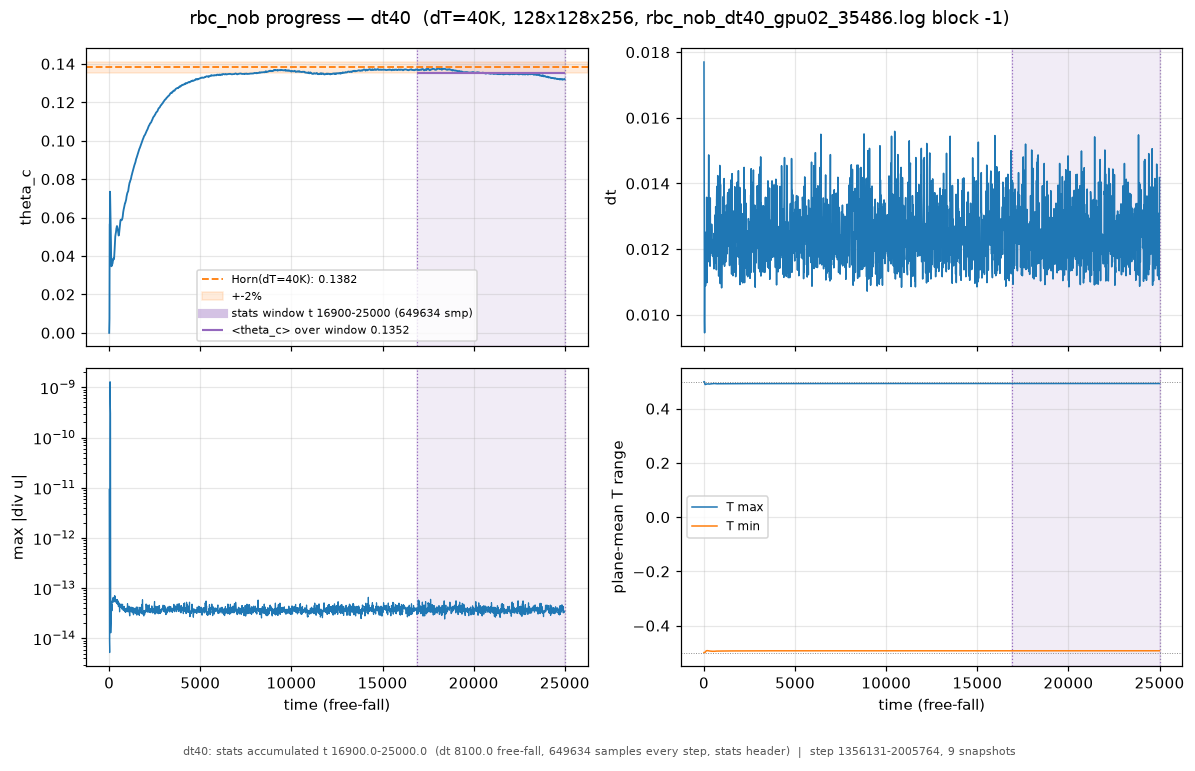

[dt40] 최근 20% 창: <theta_c>=+0.1343 (목표 대비 -2.8%), 기울기 -6.25e-07/t.u. (플래토)  dt 0.0095..0.0177, div max 1.3e-09, 0.019 s/step
           누적 구간: dt40: stats accumulated t 16900.0-25000.0  (dt 8100.0 free-fall, 649634 samples every step, stats header)  |  step 1356131-2005764, 9 snapshots


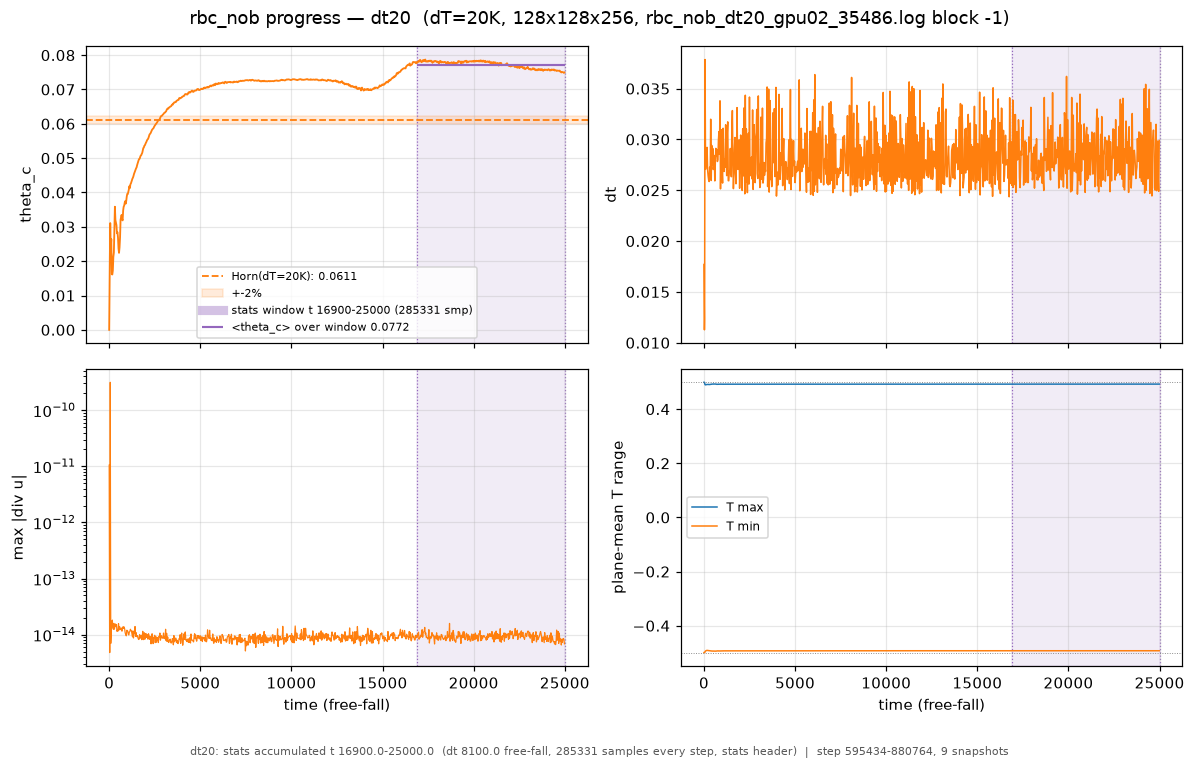

[dt20] 최근 20% 창: <theta_c>=+0.0767 (목표 대비 +25.4%), 기울기 -6.93e-07/t.u. (플래토)  dt 0.0113..0.0379, div max 3.1e-10, 0.019 s/step
           누적 구간: dt20: stats accumulated t 16900.0-25000.0  (dt 8100.0 free-fall, 285331 samples every step, stats header)  |  step 595434-880764, 9 snapshots


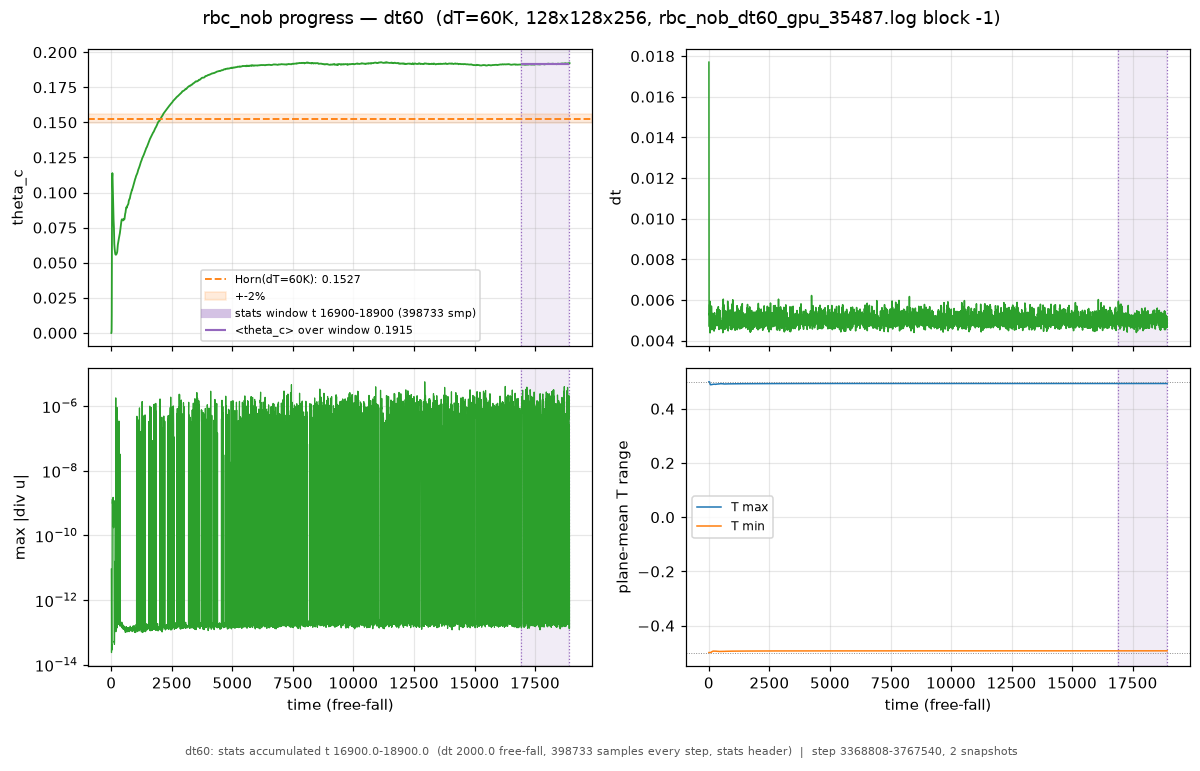

[dt60] 최근 20% 창: <theta_c>=+0.1913 (목표 대비 +25.3%), 기울기 +3.23e-07/t.u. (플래토)  dt 0.0044..0.0177, div max 5.6e-06, 0.019 s/step
           누적 구간: dt60: stats accumulated t 16900.0-18900.0  (dt 2000.0 free-fall, 398733 samples every step, stats header)  |  step 3368808-3767540, 2 snapshots


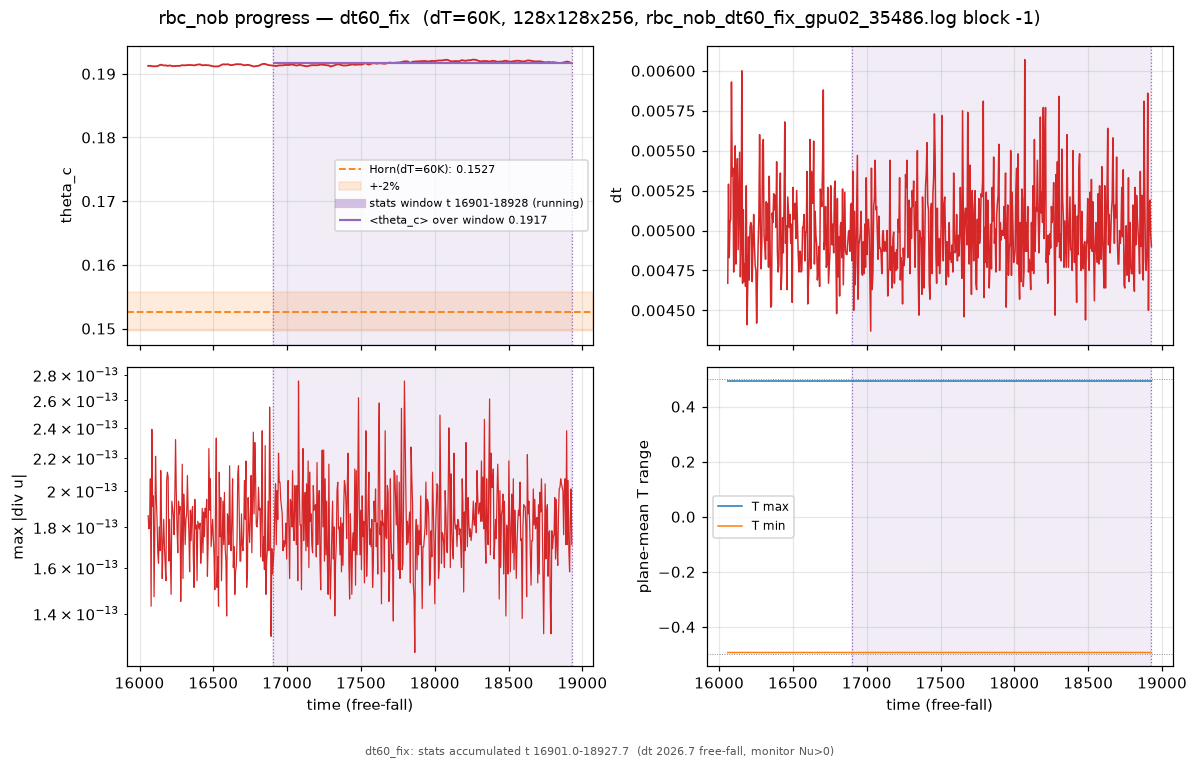

[dt60_fix] 최근 20% 창: <theta_c>=+0.1919 (목표 대비 +25.7%), 기울기 -4.32e-07/t.u. (플래토)  dt 0.0044..0.0061, div max 2.7e-13, 0.019 s/step
           누적 구간: dt60_fix: stats accumulated t 16901.0-18927.7  (dt 2026.7 free-fall, monitor Nu>0)


In [6]:
# 케이스별 4패널 개요 — θ_c / dt / div / T 범위
# 보라색 음영 띠 = **통계를 누적한 구간** (어디서 어디까지 평균했나). 네 패널 모두
# 같은 구간을 깔아 두므로 "평균 구간 동안 dt·div 가 멀쩡했나" 를 바로 볼 수 있다.
for run in runs:
    figure, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
    axis_theta, axis_dt, axis_div, axis_range = np.ravel(axes)

    axis_theta.plot(run["time"], run["theta_c"], lw=1.2, color=run["color"])
    axis_theta.axhline(run["theta_target"], color="tab:orange", ls="--", lw=1.2,
                       label=f"Horn(dT={run['delta_temperature']:g}K): "
                             f"{run['theta_target']:.4f}")
    axis_theta.axhspan(run["theta_target"] * 0.98, run["theta_target"] * 1.02,
                       color="tab:orange", alpha=0.15, label="+-2%")
    for axis in (axis_theta, axis_dt, axis_div, axis_range):   # 누적 구간 (네 패널 공통)
        shade_window(axis, run)
    window = run["window"]
    if window is not None:                 # 범례용 더미 — 띠 색을 설명한다
        axis_theta.plot([], [], color="tab:purple", alpha=0.4, lw=6,
                        label=(f"stats window t {window['start_time']:.0f}-"
                               f"{window['end_time']:.0f}"
                               + (f" ({window['n_samples']} smp)"
                                  if window["n_samples"] else " (running)")))
        # 누적 구간 안의 θ_c 평균 = 통계 파일이 보고하는 값과 같은 창
        inside = ((run["time"] >= window["start_time"])
                  & (run["time"] <= window["end_time"]))
        if inside.any():
            axis_theta.hlines(run["theta_c"][inside].mean(), window["start_time"],
                              window["end_time"], color="tab:purple", lw=1.4,
                              label=f"<theta_c> over window "
                                    f"{run['theta_c'][inside].mean():.4f}")
    axis_theta.set_ylabel("theta_c"); axis_theta.legend(fontsize=7)

    axis_dt.plot(run["time"], run["dt"], lw=1, color=run["color"])
    axis_dt.set_ylabel("dt")

    axis_div.semilogy(run["time"], run["divergence"], lw=0.8, color=run["color"])
    axis_div.set_ylabel("max |div u|"); axis_div.set_xlabel("time (free-fall)")

    axis_range.plot(run["time"], run["temperature_max"], lw=1, label="T max")
    axis_range.plot(run["time"], run["temperature_min"], lw=1, label="T min")
    axis_range.axhline(0.5, color="gray", lw=0.6, ls=":")
    axis_range.axhline(-0.5, color="gray", lw=0.6, ls=":")
    axis_range.set_ylabel("plane-mean T range")
    axis_range.set_xlabel("time (free-fall)"); axis_range.legend(fontsize=8)

    figure.suptitle(f"rbc_nob progress — {run['label']}  "
                    f"(dT={run['delta_temperature']:g}K, {run.get('grid', '?')}, "
                    f"{os.path.basename(run['log_path'])} block {run['block_index']})")
    figure.tight_layout(rect=(0, 0.045, 1, 1))
    annotate_windows(figure, [run])
    # figure.savefig(f"progress_overview_{run['label']}.png", dpi=150)
    plt.show()

    print(f"[{run['label']}] 최근 20% 창: <theta_c>={run['tail_mean']:+.4f} "
          f"(목표 대비 {100 * (run['tail_mean'] / run['theta_target'] - 1):+.1f}%), "
          f"기울기 {run['tail_slope']:+.2e}/t.u. "
          f"({'플래토' if run['plateau'] else '아직 수렴 중'})  "
          f"dt {run['dt'].min():.4f}..{run['dt'].max():.4f}, "
          f"div max {run['divergence'].max():.1e}, "
          f"{run['seconds_per_step'][-1]:.3f} s/step")
    print(f"           누적 구간: {window_text(run)}")

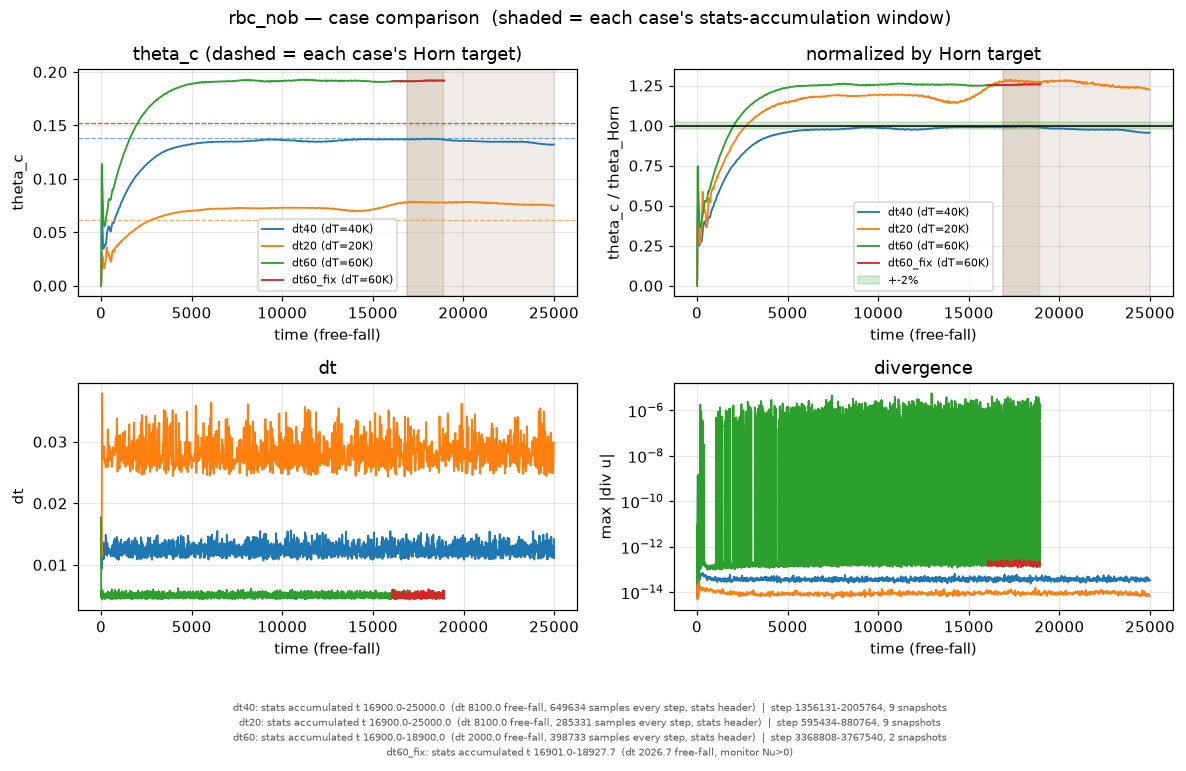

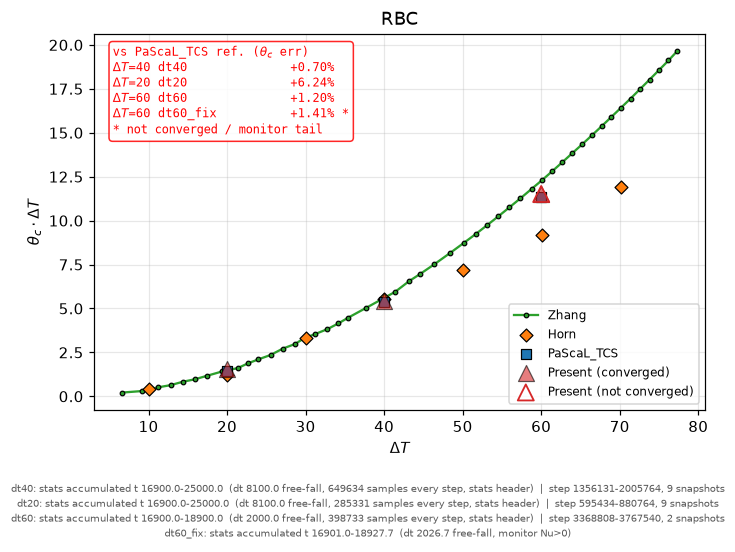

=== theta_c 비교 (참조는 같은 ΔT 로 보간) ===
  dt40               ΔT=40K  theta_c=0.1352 (x ΔT = 5.407K, stats) | Zhang 0.1400 (-3.43%) | Horn 0.1382 (-2.18%) | PaScaL_TCS 0.1342 (+0.70%)
  dt20               ΔT=20K  theta_c=0.0772 (x ΔT = 1.544K, stats) | Zhang 0.0738 (+4.53%) | Horn 0.0611 (+26.25%) | PaScaL_TCS 0.0727 (+6.24%)
  dt60               ΔT=60K  theta_c=0.1915 (x ΔT = 11.491K, stats) | Zhang 0.2044 (-6.29%) | Horn 0.1527 (+25.46%) | PaScaL_TCS 0.1892 (+1.20%)
  dt60_fix           ΔT=60K  theta_c=0.1919 (x ΔT = 11.515K, monitor tail) | Zhang 0.2044 (-6.10%) | Horn 0.1527 (+25.72%) | PaScaL_TCS 0.1892 (+1.41%)


In [7]:
# 케이스 겹친 비교 — 절대 θ_c 는 ΔT 마다 목표가 다르므로 **목표로 정규화**한
# 패널을 같이 둔다 (θ_c/θ_Horn → 1 로 모이면 NOB 응답이 ΔT 전역에서 맞는 것).
figure, axes = plt.subplots(2, 2, figsize=(11, 7))
axis_absolute, axis_normalized, axis_dt, axis_div = np.ravel(axes)

for run in runs:
    style = dict(color=run["color"], lw=1.2,
                 label=f"{run['label']} (dT={run['delta_temperature']:g}K)")
    # 케이스마다 누적 구간을 자기 색의 옅은 띠로 (θ_c 패널 둘에만 — 겹쳐도 읽힌다)
    window = run["window"]
    if window is not None:
        for axis in (axis_absolute, axis_normalized):
            axis.axvspan(window["start_time"], window["end_time"],
                         color=run["color"], alpha=0.07, zorder=0)
    axis_absolute.plot(run["time"], run["theta_c"], **style)
    axis_absolute.axhline(run["theta_target"], color=run["color"], ls="--", lw=0.8,
                          alpha=0.6)
    axis_normalized.plot(run["time"], run["theta_c"] / run["theta_target"], **style)
    axis_dt.plot(run["time"], run["dt"], **style)
    axis_div.semilogy(run["time"], run["divergence"], **style)

axis_absolute.set_ylabel("theta_c"); axis_absolute.set_xlabel("time (free-fall)")
axis_absolute.set_title("theta_c (dashed = each case's Horn target)")
axis_absolute.legend(fontsize=7)

axis_normalized.axhline(1.0, color="k", lw=1)
axis_normalized.axhspan(0.98, 1.02, color="tab:green", alpha=0.2, label="+-2%")
axis_normalized.set_ylabel("theta_c / theta_Horn")
axis_normalized.set_xlabel("time (free-fall)")
axis_normalized.set_title("normalized by Horn target"); axis_normalized.legend(fontsize=7)

axis_dt.set_ylabel("dt"); axis_dt.set_xlabel("time (free-fall)"); axis_dt.set_title("dt")
axis_div.set_ylabel("max |div u|"); axis_div.set_xlabel("time (free-fall)")
axis_div.set_title("divergence")

figure.suptitle("rbc_nob — case comparison  "
                "(shaded = each case's stats-accumulation window)")
figure.tight_layout(rect=(0, 0.03 + 0.022 * len(runs), 1, 1))
annotate_windows(figure, runs, fontsize=6.5)
# figure.savefig("case_comparison.png", dpi=150)
plt.show()

# ── fig9 — θ_c·ΔT vs ΔT  (MPM-STD_C/apps/rbc/fig9_data/plot_rbc_cases.ipynb 양식) ──
# ★ y축은 무차원 θ_c 가 아니라 **θ_c·ΔT [K]** — 참조 CSV 3종이 그 단위다.
#   Present 는 빨간 삼각형: 채움 = 플래토, 빈 것 = 아직 수렴 전.
#   θ_c 는 통계 파일 헤더(시간평균 미드플레인 — main.cpp:360 sum_theta_c)가 정본이고,
#   통계 전이면 모니터 최근 20% 평균을 대신 쓴다 (그래서 빈 삼각형).
ERROR_REFERENCE = "PaScaL_TCS"      # 그림 안 빨간 상자의 기준 ("PaScaL_TCS" / "Zhang" 도 가능)

reference_files = [("Zhang", "zhang.csv", "tab:green", "o"),
                   ("Horn", "Horm.csv", "tab:orange", "D"),
                   ("PaScaL_TCS", "PaScaL_TCS.csv", "tab:blue", "s")]
reference_curves = {}
for name, filename, color, marker in reference_files:
    reference_path = f"../../rbc/plot/{filename}"
    if not os.path.exists(reference_path):
        print(f"[ref skip] {reference_path} 없음"); continue
    reference_curves[name] = dict(data=np.genfromtxt(reference_path, delimiter=","),
                                  color=color, marker=marker)

def reference_theta_c(name, delta_temperature):
    """참조 CSV(ΔT[K], θ_c·ΔT[K])를 ΔT 로 보간 → 무차원 θ_c."""
    data = reference_curves[name]["data"]
    return float(np.interp(delta_temperature, data[:, 0], data[:, 1])) / delta_temperature

fig9_runs = [r for r in runs if r.get("fig9", True)]
for run in fig9_runs:                  # Present 값 — 통계 우선, 없으면 모니터
    if run["profile"] is not None:
        run["theta_c_present"] = run["profile"]["header"]["theta_c"]
        run["theta_c_source"] = "stats"
    else:
        run["theta_c_present"] = run["tail_mean"]
        run["theta_c_source"] = "monitor tail"

figure, axis = plt.subplots(figsize=(6.5, 5))
for name, reference in reference_curves.items():
    data = reference["data"]
    if name == "Zhang":                # 촘촘한 실험 곡선 — 선 + 작은 마커
        axis.plot(data[:, 0], data[:, 1], color=reference["color"],
                  marker=reference["marker"], markersize=3,
                  markerfacecolor=reference["color"], markeredgecolor="black",
                  markeredgewidth=0.8, zorder=4, label=name)
    else:
        axis.scatter(data[:, 0], data[:, 1], c=reference["color"],
                     marker=reference["marker"], edgecolors="black",
                     linewidths=0.8, zorder=4, label=name)

for run in fig9_runs:
    converged = run["plateau"] and run["profile"] is not None
    axis.scatter([run["delta_temperature"]],
                 [run["theta_c_present"] * run["delta_temperature"]],
                 s=110, marker="^", zorder=5,
                 c="tab:red" if converged else "none",
                 edgecolors="black" if converged else "tab:red",
                 linewidths=0.8 if converged else 1.2,
                 alpha=0.6 if converged else 1.0)
axis.scatter([], [], s=110, marker="^", c="tab:red", edgecolors="black",
             linewidths=0.8, alpha=0.6, label="Present (converged)")
axis.scatter([], [], s=110, marker="^", c="none", edgecolors="tab:red",
             linewidths=1.2, label="Present (not converged)")

axis.set_xlabel(r"$\Delta T$")
axis.set_ylabel(r"$\theta_c \cdot \Delta T$")
axis.set_title("RBC")
axis.legend(fontsize=8)

# 그림 안 빨간 오차 상자 — mathtext/ASCII 만 (DejaVu Sans 에 한글 글리프 없음).
# 케이스 라벨도 그대로 들어가므로 run_configurations 의 label 은 ASCII 로 둘 것.
if ERROR_REFERENCE in reference_curves and fig9_runs:
    error_lines = [rf"vs {ERROR_REFERENCE} ref. ($\theta_c$ err)"]
    for run in fig9_runs:
        target = reference_theta_c(ERROR_REFERENCE, run["delta_temperature"])
        error = (run["theta_c_present"] / target - 1) * 100
        flag = "" if run["profile"] is not None and run["plateau"] else " *"
        error_lines.append(rf"$\Delta T$={run['delta_temperature']:g} "
                           f"{run['label'][:16]:16s}{error:+7.2f}%{flag}")
    if any(not (r["profile"] is not None and r["plateau"]) for r in fig9_runs):
        error_lines.append("* not converged / monitor tail")
    axis.text(0.03, 0.97, "\n".join(error_lines), transform=axis.transAxes,
              color="red", fontsize=8, va="top", ha="left", family="monospace",
              bbox=dict(boxstyle="round", facecolor="white", edgecolor="red",
                        alpha=0.85))

figure.tight_layout(rect=(0, 0.02 + 0.027 * len(fig9_runs), 1, 1))
annotate_windows(figure, fig9_runs, fontsize=6.5)
# figure.savefig("fig9_theta_c_cases.png", dpi=150)
plt.show()

print("=== theta_c 비교 (참조는 같은 ΔT 로 보간) ===")
for run in fig9_runs:
    parts = [f"{run['label']:18s} ΔT={run['delta_temperature']:g}K  "
             f"theta_c={run['theta_c_present']:.4f} "
             f"(x ΔT = {run['theta_c_present'] * run['delta_temperature']:.3f}K, "
             f"{run['theta_c_source']})"]
    for name in reference_curves:
        target = reference_theta_c(name, run["delta_temperature"])
        parts.append(f"{name} {target:.4f} "
                     f"({100 * (run['theta_c_present'] / target - 1):+.2f}%)")
    print("  " + " | ".join(parts))

[dt40] ../stats_nob_dt40/rbc_nob_stats_02005764.dat: samples=649634, theta_c=+0.13518 (-2.18% vs Horn), Nu=9.499
  열 경계층 (벽 기울기 자): lambda_bot=0.03849 lambda_top=0.06583  비대칭 top/bot=1.710
  누적 구간: dt40: stats accumulated t 16900.0-25000.0  (dt 8100.0 free-fall, 649634 samples every step, stats header)  |  step 1356131-2005764, 9 snapshots


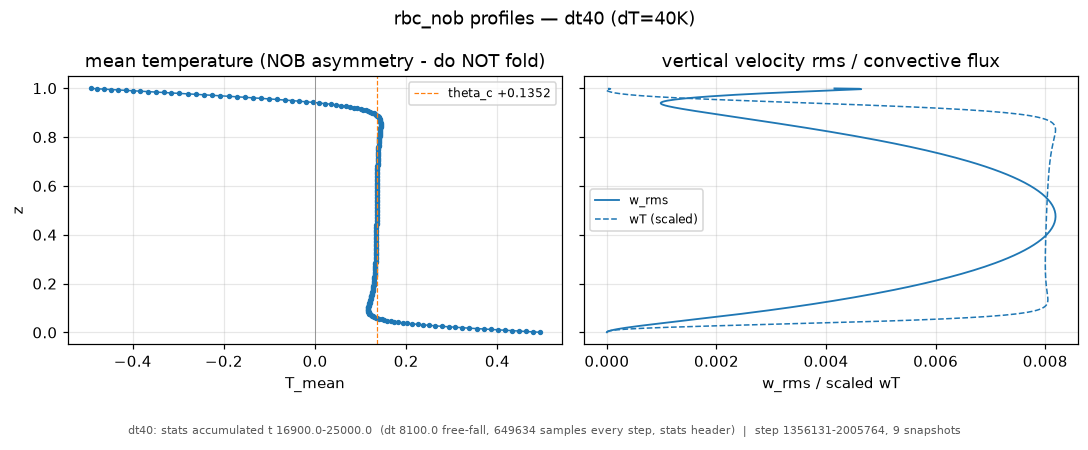

[dt20] ../stats_nob_dt20/rbc_nob_stats_00880764.dat: samples=285331, theta_c=+0.07719 (+26.25% vs Horn), Nu=9.770
  열 경계층 (벽 기울기 자): lambda_bot=0.04339 lambda_top=0.05873  비대칭 top/bot=1.353
  누적 구간: dt20: stats accumulated t 16900.0-25000.0  (dt 8100.0 free-fall, 285331 samples every step, stats header)  |  step 595434-880764, 9 snapshots


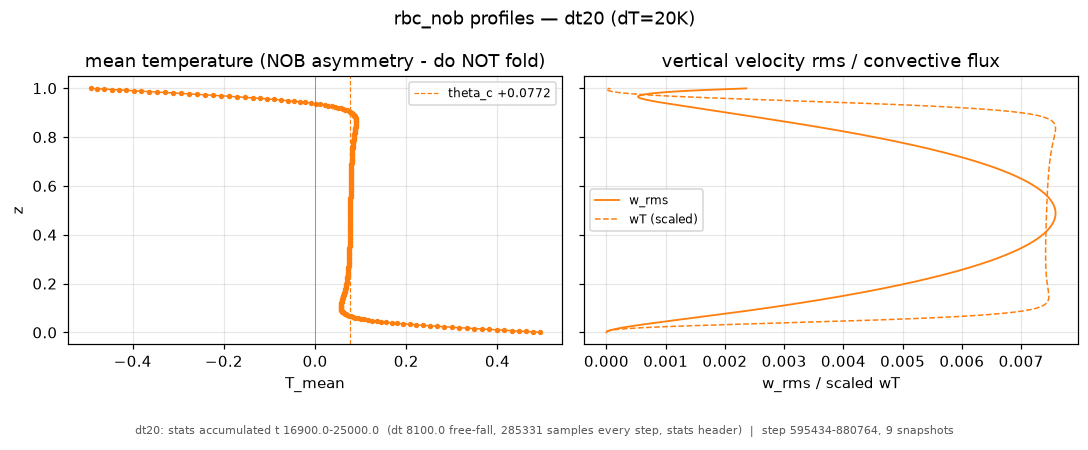

[dt60] ../stats_nob_dt60/rbc_nob_stats_03767540.dat: samples=398733, theta_c=+0.19152 (+25.46% vs Horn), Nu=9.149
  열 경계층 (벽 기울기 자): lambda_bot=0.03352 lambda_top=0.07343  비대칭 top/bot=2.191
  누적 구간: dt60: stats accumulated t 16900.0-18900.0  (dt 2000.0 free-fall, 398733 samples every step, stats header)  |  step 3368808-3767540, 2 snapshots


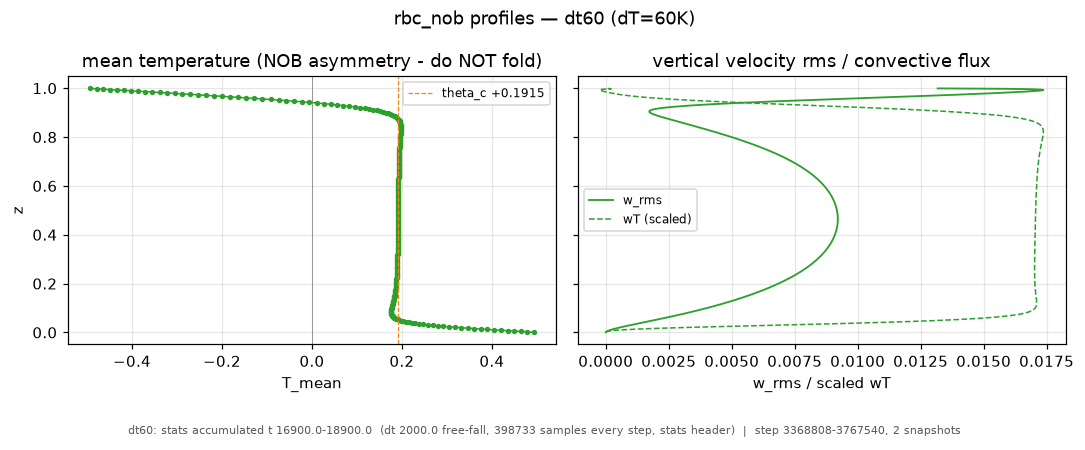

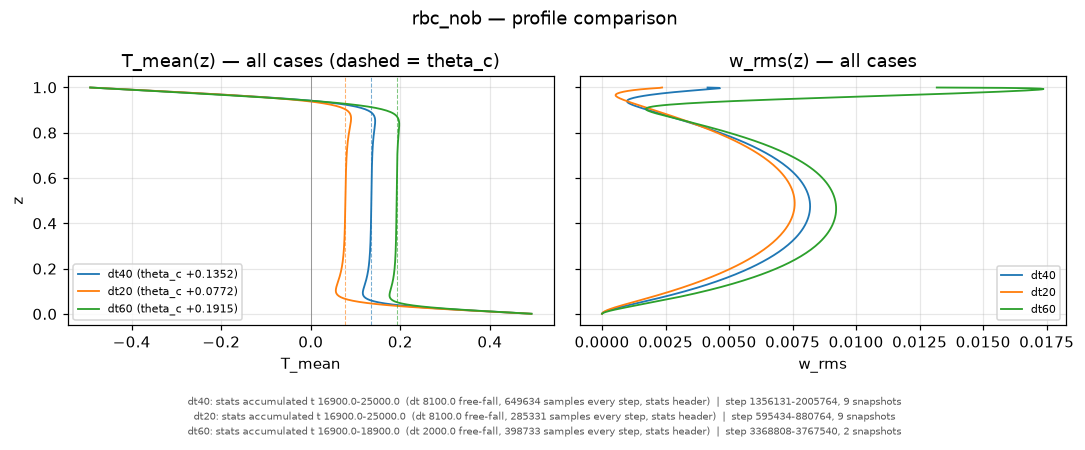

In [8]:
# 통계 프로파일 — 케이스마다 T_mean(z)·w_rms·wT, 그리고 케이스 겹친 T_mean(z).
# NOB 신호는 상·하 비대칭이므로 **접기 평균 금지**.
profiled = [r for r in runs if r["profile"]]
if not profiled:
    print("통계 파일이 있는 케이스가 없다 — 본런이 stats_start_time 을 지나면 생긴다")
for run in profiled:
    profile = run["profile"]; header = profile["header"]
    z, temperature_mean = profile["z"], profile["temperature_mean"]
    theta_c = header["theta_c"]
    lambda_bottom, lambda_top = boundary_layer_thicknesses(z, temperature_mean, theta_c)
    print(f"[{run['label']}] {profile['path']}: samples={int(header['samples'])}, "
          f"theta_c={theta_c:+.5f} "
          f"({100 * (theta_c / run['theta_target'] - 1):+.2f}% vs Horn), "
          f"Nu={header['Nu_volume']:.3f}")
    print(f"  열 경계층 (벽 기울기 자): lambda_bot={lambda_bottom:.5f} "
          f"lambda_top={lambda_top:.5f}  비대칭 top/bot={lambda_top / lambda_bottom:.3f}")
    print(f"  누적 구간: {window_text(run)}")

    figure, (axis_t, axis_w) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    axis_t.plot(temperature_mean, z, "-o", ms=2.5, lw=1, color=run["color"])
    axis_t.axvline(theta_c, color="tab:orange", ls="--", lw=0.8,
                   label=f"theta_c {theta_c:+.4f}")
    axis_t.axvline(0, color="gray", lw=0.5)
    axis_t.set_xlabel("T_mean"); axis_t.set_ylabel("z"); axis_t.legend(fontsize=8)
    # 그림 문자열은 ASCII/그리스만 — DejaVu Sans 에 한글 글리프가 없다
    axis_t.set_title("mean temperature (NOB asymmetry - do NOT fold)")
    scale = profile["w_rms"].max() / max(abs(profile["wt_mean"]).max(), 1e-30)
    axis_w.plot(profile["w_rms"], z, lw=1.2, color=run["color"], label="w_rms")
    axis_w.plot(profile["wt_mean"] * scale, z, lw=1, ls="--", color=run["color"],
                label="wT (scaled)")
    axis_w.set_xlabel("w_rms / scaled wT"); axis_w.legend(fontsize=8)
    axis_w.set_title("vertical velocity rms / convective flux")
    figure.suptitle(f"rbc_nob profiles — {run['label']} "
                    f"(dT={run['delta_temperature']:g}K)")
    figure.tight_layout(rect=(0, 0.075, 1, 1))
    annotate_windows(figure, [run])
    # figure.savefig(f"profiles_latest_{run['label']}.png", dpi=150)
    plt.show()

if len(profiled) > 1:                  # 케이스 겹친 평균온도 — ΔT 별 비대칭 비교
    figure, (axis_t, axis_w) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    for run in profiled:
        profile = run["profile"]
        axis_t.plot(profile["temperature_mean"], profile["z"], lw=1.2,
                    color=run["color"],
                    label=f"{run['label']} (theta_c "
                          f"{profile['header']['theta_c']:+.4f})")
        axis_t.axvline(profile["header"]["theta_c"], color=run["color"], ls="--",
                       lw=0.7, alpha=0.6)
        axis_w.plot(profile["w_rms"], profile["z"], lw=1.2, color=run["color"],
                    label=run["label"])
    axis_t.axvline(0, color="gray", lw=0.5)
    axis_t.set_xlabel("T_mean"); axis_t.set_ylabel("z"); axis_t.legend(fontsize=7)
    axis_t.set_title("T_mean(z) — all cases (dashed = theta_c)")
    axis_w.set_xlabel("w_rms"); axis_w.legend(fontsize=7)
    axis_w.set_title("w_rms(z) — all cases")
    figure.suptitle("rbc_nob — profile comparison")
    figure.tight_layout(rect=(0, 0.02 + 0.033 * len(profiled), 1, 1))
    annotate_windows(figure, profiled, fontsize=6.5)
    # figure.savefig("profile_comparison.png", dpi=150)
    plt.show()

## 확장 통계 (Horn 2013 전 항목) — ΔT = 40 K 윗벽 rms 스파이크 dt 스터디 (2026-10-09)

`extended_cases` 의 케이스마다 `../stats_nob_dt40_<case>/rbc_nob_stats_<step>.dat`(헤더 스칼라 + 11열) 과
`rbc_nob_tpdf_<step>.dat`(온도 PDF), 그리고 14열 모니터 로그(`Nu_b Nu_t D_x u_bot_max u_top_max` 추가)를 읽는다.
세 케이스는 모두 `checkpoints/rbc_nob_ck_02005764.bin`(t = 25000) warm restart 이고 dt 만 다르다
(base = CFL dt ≈ 0.012, D_× ≈ 39 / visc12 = C_v 12 → D_× 12 / visc6 = C_v 6 → D_× 6).
설계·유도는 `docs/Design/20261009_rbc_nob_dt_criterion.md`. Horn 참조값(Ra = 10⁶, ΔT 별)은 `horn2013_ra1e6_deltaT.csv`
(fig.5b·12b·15b 눈금 판독, ±0.05 수준).

In [ ]:
# ── 확장 통계 로더 ─────────────────────────────────────────────────────────
extended_cases = [
    dict(label="base (CFL dt, D_x~39)", stats_dir="../stats_nob_dt40_base",   log_glob="../log/dt40_base_*.log"),
    dict(label="visc30 (C_v=30, scan)", stats_dir="../stats_nob_dt40_visc30", log_glob="../log/dt40_visc30_*.log"),
    dict(label="visc24 (C_v=24, scan)", stats_dir="../stats_nob_dt40_visc24", log_glob="../log/dt40_visc24_*.log"),
    dict(label="visc18 (C_v=18, scan)", stats_dir="../stats_nob_dt40_visc18", log_glob="../log/dt40_visc18_*.log"),
    dict(label="visc12 (C_v=12)",       stats_dir="../stats_nob_dt40_visc12", log_glob="../log/dt40_visc12_*.log"),
    dict(label="visc6 (C_v=6)",         stats_dir="../stats_nob_dt40_visc6",  log_glob="../log/dt40_visc6_*.log"),
    # dict(label="smoke_ext (32^3)", stats_dir="../stats_nob_smoke_ext", log_glob="../log/smoke_ext_*.log"),
]
EXTENDED_COLUMNS = ["z", "T_mean", "u_rms", "v_rms", "w_rms", "T_rms", "wT_mean", "Nu_z",
                    "kappa_mean", "mu_mean", "ke_mean"]
EXTENDED_MONITOR = ["step", "time", "dt", "div", "theta_c", "Nu", "Tmin", "Tmax", "Nu_b", "Nu_t",
                    "D_x", "u_bot_max", "u_top_max", "sec_per_step"]

def load_extended(stats_dir):
    """최신 확장 통계 파일 → dict(헤더 스칼라, 열 배열, uh_rms, 면 좌표, PDF). 없으면 None."""
    paths = sorted(glob.glob(f"{stats_dir}/rbc_nob_stats_*.dat"))
    if not paths:
        return None
    header, rows = {}, []
    for line in open(paths[-1]):
        if line.startswith("#"):
            for key, value in re.findall(r"(\w+)=([-\d.eE+]+)", line):
                header[key] = float(value)
            continue
        rows.append([float(x) for x in line.split()])
    data = np.array(rows)
    out = dict(path=paths[-1], header=header, n_snapshots=len(paths))
    out.update({name: data[:, i] for i, name in enumerate(EXTENDED_COLUMNS)})
    out["uh_rms"] = np.hypot(out["u_rms"], out["v_rms"])
    # w_rms·wT·ke 는 MAC 면 (행 k = 셀 k 아래 면, 행 0 = 바닥 벽면) — 면 좌표를 복원한다
    z = out["z"]
    z_face = np.concatenate([[0.0], 0.5 * (z[1:] + z[:-1])])
    out["z_face"] = z_face
    pdf_paths = sorted(glob.glob(f"{stats_dir}/rbc_nob_tpdf_*.dat"))
    out["pdf"] = np.loadtxt(pdf_paths[-1], comments="#") if pdf_paths else None
    return out

def load_extended_monitor(log_glob):
    """14열 모니터 로그(최신 파일) → 열 이름 dict. 없으면 None."""
    paths = sorted(glob.glob(log_glob))
    if not paths:
        return None
    rows = []
    for line in open(paths[-1]):
        parts = line.split()
        if len(parts) == len(EXTENDED_MONITOR) and not line.lstrip().startswith("#"):
            try:
                rows.append([float(x) for x in parts])
            except ValueError:
                pass
    if not rows:
        return None
    data = np.array(rows)
    return {name: data[:, i] for i, name in enumerate(EXTENDED_MONITOR)}

def spike_ratio(profile, face=3):
    """윗벽/아랫벽 w_rms 비 — 벽에서 `face` 번째 MAC 면끼리 (행 n−face ↔ 행 face)."""
    w = profile["w_rms"]
    return float(w[len(w) - face] / max(w[face], 1e-300))

extended_runs = []
for case in extended_cases:
    profile = load_extended(case["stats_dir"])
    monitor = load_extended_monitor(case["log_glob"])
    if profile is None and monitor is None:
        print(f"[{case['label']}] 아직 파일 없음 — 건너뜀")
        continue
    extended_runs.append(dict(case, profile=profile, monitor=monitor))
    if profile is not None:
        h = profile["header"]
        print(f"[{case['label']}] {os.path.basename(profile['path'])}  창 t {h['t_start']:.0f}-{h['t']:.0f} "
              f"(sum_dt {h['sum_dt']:.0f}, {profile['n_snapshots']} 파일)  theta_c {h['theta_c']:.4f}  "
              f"Nu_vol {h['Nu_volume']:.3f}  Nu_b/Nu_t {h['Nu_bottom']:.3f}/{h['Nu_top']:.3f}  "
              f"spike(top/bottom, 3rd face) {spike_ratio(profile):.1f}")
    if monitor is not None:
        print(f"    monitor: t {monitor['time'][0]:.0f}-{monitor['time'][-1]:.0f}, dt {np.median(monitor['dt']):.2e}, "
              f"D_x {np.median(monitor['D_x']):.1f}, u_top_max/u_bot_max "
              f"{np.median(monitor['u_top_max']) / max(np.median(monitor['u_bot_max']), 1e-300):.2f}")

horn_path = "horn2013_ra1e6_deltaT.csv"
horn_ra1e6 = (np.genfromtxt(horn_path, delimiter=",", names=True, comments="#")
              if os.path.exists(horn_path) else None)
def horn_value(column, delta_temperature=40.0):
    if horn_ra1e6 is None or column not in horn_ra1e6.dtype.names:
        return float("nan")
    return float(np.interp(delta_temperature, horn_ra1e6["deltaT"], horn_ra1e6[column]))

In [ ]:
# ── 스파이크 그림: 벽에서의 거리별 w_rms·u_h,rms (아랫벽 실선, 윗벽 점선) ───────
# 수치 artefact 라면 윗벽 곡선이 케이스(dt)에 따라 내려오고, 아랫벽은 그대로여야 한다.
profiled = [r for r in extended_runs if r["profile"] is not None]
if profiled:
    figure, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for color, run in zip(colors, profiled):
        p = run["profile"]
        z, zf = p["z"], p["z_face"]
        # 아랫벽: 거리 = z (셀) / zf (면);  윗벽: 1 − z, 1 − zf
        axes[0].loglog(zf[1:], p["w_rms"][1:], "-", color=color, label=f"{run['label']} bottom")
        axes[0].loglog(1 - zf[1:], p["w_rms"][1:], "--", color=color, label=f"{run['label']} top")
        axes[1].loglog(z, p["uh_rms"], "-", color=color)
        axes[1].loglog(1 - z, p["uh_rms"], "--", color=color)
        axes[2].loglog(z, p["T_rms"], "-", color=color)
        axes[2].loglog(1 - z, p["T_rms"], "--", color=color)
    for ax, title in zip(axes, ["w_rms (MAC face)", "u_h,rms = sqrt(u_rms^2+v_rms^2)", "T_rms"]):
        ax.set_xlabel("distance from wall"); ax.set_title(title); ax.set_xlim(1e-3, 0.5)
    axes[0].legend(fontsize=8)
    figure.suptitle("Near-wall rms vs distance from wall: solid = bottom (hot, low mu), dashed = top (cold, high mu)")
    figure.tight_layout(); plt.show()
    print("spike ratio top/bottom at k-th MAC face from wall (w_rms):")
    for run in profiled:
        print(f"  {run['label']:24s}", "  ".join(f"k={k}: {spike_ratio(run['profile'], k):7.1f}" for k in (1, 2, 3, 5, 8, 12)))

In [ ]:
# ── Horn fig.9(c,d) 식: u_h,rms(z) 와 w_rms(z) 세로축 z, 가로축 log ──────────
if profiled:
    figure, axes = plt.subplots(1, 2, figsize=(11, 4.8))
    for run in profiled:
        p = run["profile"]
        axes[0].semilogx(p["uh_rms"], p["z"], label=run["label"])
        axes[1].semilogx(p["w_rms"][1:], p["z_face"][1:], label=run["label"])
    axes[0].set_xlabel("<u_h,rms>_xy,t (Horn: <u_r,rms>)"); axes[0].set_ylabel("z/H")
    axes[1].set_xlabel("<w_rms>_xy,t (Horn: <u_z,rms>)"); axes[1].set_ylabel("z/H")
    for ax in axes:
        ax.set_ylim(0, 1); ax.legend(fontsize=8)
    figure.suptitle("rms profiles (Horn 2013 fig.9 style) — Ra=1e6, dT=40K; Horn fig.9(d): u_r,rms ~1e-4..1e-3 bulk, no near-wall spike")
    figure.tight_layout(); plt.show()

In [ ]:
# ── 평균 온도·T_rms·Nu(z)·물성 프로파일 ────────────────────────────────────
if profiled:
    figure, axes = plt.subplots(1, 4, figsize=(17, 4.4))
    for run in profiled:
        p, h = run["profile"], run["profile"]["header"]
        axes[0].plot(p["T_mean"], p["z"], label=run["label"])
        axes[1].plot(p["T_rms"], p["z"], label=run["label"])
        axes[2].plot(p["Nu_z"], p["z"], label=f"{run['label']} (vol {h['Nu_volume']:.2f}, wall {h['Nu_bottom']:.2f}/{h['Nu_top']:.2f})")
        axes[3].semilogx(p["mu_mean"], p["z"], "-", label=f"{run['label']} mu")
        axes[3].semilogx(p["kappa_mean"], p["z"], ":", label=f"{run['label']} kappa")
    for run in profiled[:1]:
        h = run["profile"]["header"]
        axes[0].axhline(h["lambda_theta_b"], color="gray", ls=":", lw=0.8)
        axes[0].axhline(1 - h["lambda_theta_t"], color="gray", ls=":", lw=0.8)
        axes[0].axvline(h["theta_c"], color="gray", ls="--", lw=0.8)
    axes[0].set_xlabel("T_mean"); axes[1].set_xlabel("T_rms"); axes[2].set_xlabel("Nu(z)")
    axes[3].set_xlabel("mu_mean (solid), kappa_mean (dotted)")
    for ax in axes:
        ax.set_ylabel("z/H"); ax.set_ylim(0, 1); ax.legend(fontsize=7)
    figure.suptitle("Mean profiles — dotted gray: lambda_theta slope thicknesses (4.2)(4.3), dashed: theta_c")
    figure.tight_layout(); plt.show()

In [ ]:
# ── 스칼라 표: Horn 2013 과 대조 ────────────────────────────────────────────
# Nu 는 Γ=1 원통(Horn) vs 6×6×1 주기 박스(우리) 라 절대값보다 NOB/OB 비·ΔT 추세가 의미 있다.
if profiled:
    keys = [("theta_c", "theta_c"), ("Nu_volume", "Nu_NOB"), ("Nu_bottom", None), ("Nu_top", None),
            ("lambda_theta_b", None), ("lambda_theta_t", None), ("chi_lambda_theta", "chi_lambda_theta"),
            ("lambda_u_b", None), ("lambda_u_t", None), ("chi_lambda_u", "chi_lambda_u"),
            ("Re_E_m", "Re_E_m"), ("Re_E_c", "Re_E_c"), ("T_rms_center", None), ("U_E", None)]
    width = max(len(r["label"]) for r in profiled) + 2
    print(f"{'quantity':18s}" + "".join(f"{r['label']:>{width}s}" for r in profiled) + f"{'Horn(dT=40)':>14s}")
    for key, horn_key in keys:
        row = f"{key:18s}"
        for run in profiled:
            value = run["profile"]["header"].get(key, float("nan"))
            row += f"{value:>{width}.4f}"
        reference = horn_theta_c(40.0) if horn_key == "theta_c" else (horn_value(horn_key) if horn_key else float("nan"))
        row += f"{reference:>14.4f}" if reference == reference else f"{'-':>14s}"
        print(row)
    row = f"{'spike w 3rd face':18s}"
    for run in profiled:
        row += f"{spike_ratio(run['profile']):>{width}.1f}"
    print(row + f"{'~1 (symm.)':>14s}")

In [ ]:
# ── 모니터: dt, D_x, 벽 인접 평면 max|U| (윗벽/아랫벽), 벽 Nu ─────────────────
monitored = [r for r in extended_runs if r["monitor"] is not None]
if monitored:
    figure, axes = plt.subplots(2, 2, figsize=(13, 7.5))
    for run in monitored:
        m = run["monitor"]
        axes[0, 0].semilogy(m["time"], m["dt"], label=run["label"])
        axes[0, 1].plot(m["time"], m["D_x"], label=run["label"])
        axes[1, 0].semilogy(m["time"], m["u_top_max"], "--", label=f"{run['label']} top")
        axes[1, 0].semilogy(m["time"], m["u_bot_max"], "-", label=f"{run['label']} bottom")
        axes[1, 1].plot(m["time"], m["Nu_b"], "-", label=f"{run['label']} Nu_b")
        axes[1, 1].plot(m["time"], m["Nu_t"], "--", label=f"{run['label']} Nu_t")
    axes[0, 0].set_ylabel("dt"); axes[0, 1].set_ylabel("D_x = Cmu mu_max dt / (dh dz_wall)")
    axes[1, 0].set_ylabel("max|U| in wall-adjacent plane"); axes[1, 1].set_ylabel("instantaneous wall Nu")
    for ax in axes.flat:
        ax.set_xlabel("t"); ax.legend(fontsize=7)
    figure.suptitle("Monitor — if the top-wall spike is the explicit cross-stress coupling, u_top_max should fall with D_x while u_bot_max stays")
    figure.tight_layout(); plt.show()

In [ ]:
# ── 온도 PDF (Horn fig.8 식) ───────────────────────────────────────────────
with_pdf = [r for r in profiled if r["profile"]["pdf"] is not None]
if with_pdf:
    figure, ax = plt.subplots(figsize=(7, 4.4))
    for run in with_pdf:
        pdf = run["profile"]["pdf"]
        ax.semilogy(pdf[:, 0], pdf[:, 1], label=run["label"])
        ax.axvline(run["profile"]["header"]["theta_c"], ls=":", lw=0.8, color="gray")
    ax.set_xlabel("T (dimensionless, walls at +-0.5)"); ax.set_ylabel("pdf (volume- and dt-weighted)")
    ax.set_xlim(-0.5, 0.5); ax.set_ylim(1e-3, None); ax.legend(fontsize=8)
    ax.set_title("Temperature PDF — NOB: peak shifted to theta_c > 0 (Horn fig.8: skewed, peak at T_c)")
    figure.tight_layout(); plt.show()